In [1]:
import numpy as np 
import matplotlib.pyplot as plt
import scipy 
from plotting_helper import *
from parameters import *
%matplotlib inline

figures_path = 'figures/'
palette = plt.rcParams['axes.prop_cycle'].by_key()['color']  

In [2]:
def diff_assump(parameters, state_var, dt , elong_fun):

    
    x_vec = state_var[0]   #free mRNA concentrations
    xr_vec = state_var[1]  # bound mRNA ribosome concentrations
    y_vec = state_var[2]   #protein concentrations
    r = parameters['R'] - np.sum(xr_vec)  #concentration of free ribosomes


    new_x_vec = x_vec + dt * (-parameters['α']    * r * x_vec  + parameters['β']* xr_vec)
    new_xr_vec = xr_vec + dt * (parameters['α'] * r *  x_vec - parameters['β'] * xr_vec)
    new_y_vec = y_vec + dt * (parameters['β']  * xr_vec - parameters['γ'] * y_vec)

    return new_x_vec, new_xr_vec, new_y_vec


In [3]:
sim_time = 500
dt = 0.001

In [4]:
sampling = 1000 #resolution of recorded data points to check equilibrium state
results_lp = np.zeros([Rs.shape[0], int(sim_time/dt/sampling),3,N])

 
#prepare parameter dictionary
parameters = dict()
parameters['α'] = α
parameters['β'] = α/l_samples
parameters['γ'] = γ
parameters['l'] = l_samples
parameters['lp'] = stiffness_fun(parameters['l'],stiffness_fac)


x0 = np.ones([N])*x_init
init_state =np.array([x0, np.zeros([N]),np.zeros([N])]) 


for r in range(Rs.shape[0]):

    parameters['R'] = Rs[r]
    res = simulation_wrapper(init_state,parameters,diff_assump,R_fernandes, sim_time, dt, [True, sampling]) 
    results_lp[r]= res

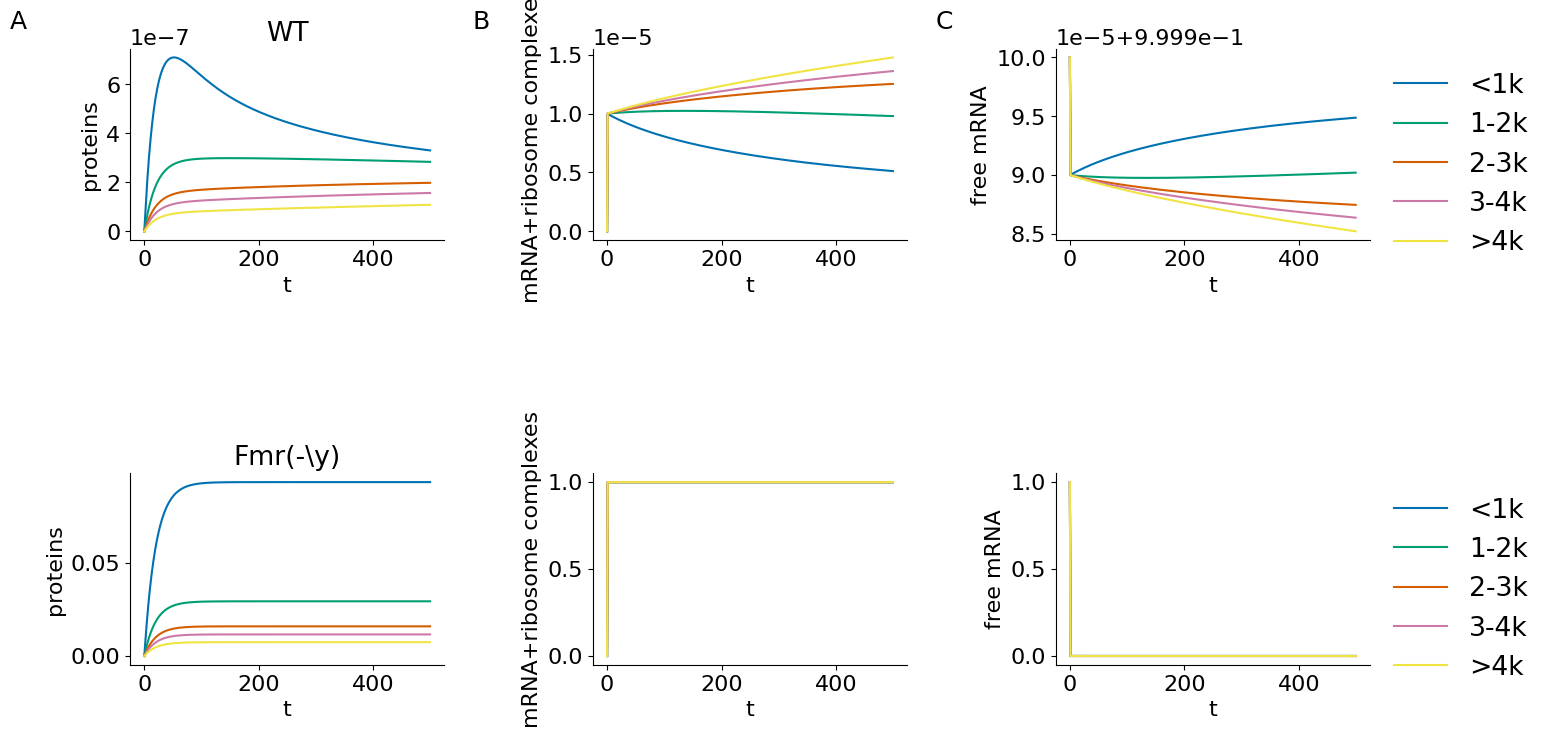

In [5]:
#check that all variables reach their equilibrium state (at minimal and maximal ribosome concetration)

layout = '''
    AABBC
    AABBC
    AABBC
    '''

fig = plt.figure(figsize=(16, 8))

height_ratios = [1,0.1,1]
width_ratios = [1,0.2,1,0.2,1]


specs, gs = panel_specs(layout, fig=fig)
gs.set_height_ratios(height_ratios)
gs.set_width_ratios(width_ratios)
gs.hspace=0.8
axes = {}
for letter in 'ABC':
    axes[letter] = ax = fig.add_subplot(specs[letter])
label_panels(axes, letters='ABC', postfix='', offset_left=1.2)
for a in list('ABC'):
    axes[a].set_axis_off()

ylabels = ['proteins', 'mRNA+ribosome complexes', 'free mRNA']
ribo_state= ['WT', 'Fmr(-\y)']
ribo_ind = [0,-1]

for j in range(2): 
    for i in range(3): 
        ax = fig.add_subplot(gs[j*2,i*2])
        if i ==0: 
            ax.set_title(ribo_state[j])
        av1 = np.mean(results_lp[ribo_ind[j],:,2-i,s_1k], axis = 0)
        av2 = np.mean(results_lp[ribo_ind[j],:,2-i,s_2k], axis = 0)
        av3 = np.mean(results_lp[ribo_ind[j],:,2-i,s_3k], axis = 0)
        av4 = np.mean(results_lp[ribo_ind[j],:,2-i,s_4k], axis = 0)
        av5 = np.mean(results_lp[ribo_ind[j],:,2-i,b_4k], axis = 0)

        ax.plot(np.arange(0,sim_time,dt*sampling), av1, label = '<1k')
        ax.plot(np.arange(0,sim_time,dt*sampling), av2, label = '1-2k')
        ax.plot(np.arange(0,sim_time,dt*sampling), av3, label = '2-3k')
        ax.plot(np.arange(0,sim_time,dt*sampling), av4, label = '3-4k')
        ax.plot(np.arange(0,sim_time,dt*sampling), av5, label = '>4k')
        ax.set_xlabel('t')
        ax.set_ylabel(ylabels[i])
        if i == 2: 
            ax.legend(bbox_to_anchor=(1.0, 1.0), loc='upper left',  frameon = False)
        clear_axes(ax)

plt.show()




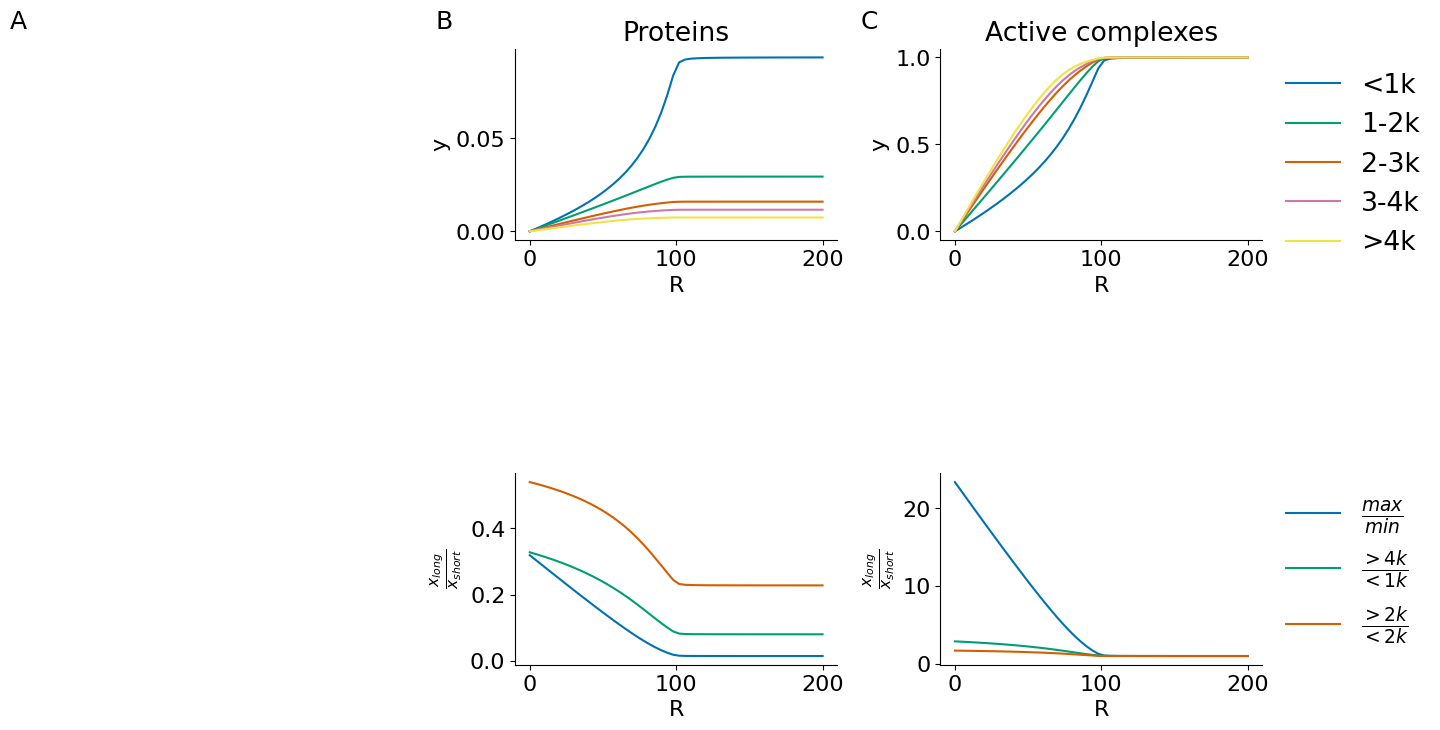

In [6]:
#figure for publication

layout = '''
    AABBCC
    AABBCC
    AABBCC
    '''



fig = plt.figure(figsize=(16, 8))

height_ratios = [1,0.1, 1]
width_ratios = [1,0.1,1,0.1,1,0.1]


specs, gs = panel_specs(layout, fig=fig)
gs.set_height_ratios(height_ratios)
gs.set_width_ratios(width_ratios)
gs.hspace=0.8
axes = {}
for letter in 'ABC':
    axes[letter] = ax = fig.add_subplot(specs[letter])
label_panels(axes, letters='ABC', postfix='', offset_left=.8)
for a in list('ABC'):
    axes[a].set_axis_off()
                 

ax = fig.add_subplot(gs[0,2])
av1 = np.mean(results_lp[:,-1, 2,s_1k], axis = 1)
av2 = np.mean(results_lp[:,-1, 2,s_2k], axis = 1)
av3 = np.mean(results_lp[:,-1, 2,s_3k], axis = 1)
av4 = np.mean(results_lp[:,-1, 2,s_4k], axis = 1)
av5 = np.mean(results_lp[:,-1, 2,b_4k], axis = 1)

ax.plot(Rs, av1, label = '<1k')
ax.plot(Rs, av2, label = '1-2k')
ax.plot(Rs, av3, label = '2-3k')
ax.plot(Rs, av4, label = '3-4k')
ax.plot(Rs, av5, label = '>4k')
ax.set_ylabel('y')
ax.set_xlabel('R')
ax.set_title('Proteins')
clear_axes(ax)

ax = fig.add_subplot(gs[0,4])
av1 = np.mean(results_lp[:,-1, 1,s_1k], axis = 1)
av2 = np.mean(results_lp[:,-1, 1,s_2k], axis = 1)
av3 = np.mean(results_lp[:,-1, 1,s_3k], axis = 1)
av4 = np.mean(results_lp[:,-1, 1,s_4k], axis = 1)
av5 = np.mean(results_lp[:,-1, 1,b_4k], axis = 1)

ax.plot(Rs, av1, label = '<1k')
ax.plot(Rs, av2, label = '1-2k')
ax.plot(Rs, av3, label = '2-3k')
ax.plot(Rs, av4, label = '3-4k')
ax.plot(Rs, av5, label = '>4k')
ax.set_ylabel('y')
ax.set_xlabel('R')
ax.set_title('Active complexes')
ax.legend(bbox_to_anchor=(1.0, 1.0), loc='upper left',  frameon = False)
clear_axes(ax)


ax = fig.add_subplot(gs[2,2])
ax.plot(Rs, results_lp[:,-1,2,-1]/results_lp[:,-1,2,0], label = '$\\frac{max}{min}$', color = palette[0])
ax.plot(Rs, np.mean(results_lp[:,-1,2,b_4k], axis = 1)/np.mean(results_lp[:,-1,2,s_1k], axis = 1), label = '$\\frac{>4k}{<1k}$', color = palette[1])
ax.plot(Rs, np.mean(results_lp[:,-1,2,long_ind], axis = 1)/np.mean(results_lp[:,-1,2,short_ind], axis = 1), label = '\\frac{>4k}{<1k}', color = palette[2])
ax.set_xlabel('R')
ax.set_ylabel('$\\frac{x_{long}}{x_{short}}$')
clear_axes(ax)

ax = fig.add_subplot(gs[2,4])
ax.plot(Rs, results_lp[:,-1,1,-1]/results_lp[:,-1,1,0], label = '$\\frac{max}{min}$', color = palette[0])
ax.plot(Rs, np.mean(results_lp[:,-1,1,b_4k], axis = 1)/np.mean(results_lp[:,-1,1,s_1k], axis = 1), label = '$\\frac{>4k}{<1k}$', color = palette[1])
ax.plot(Rs, np.mean(results_lp[:,-1,1,long_ind], axis = 1)/np.mean(results_lp[:,-1,1,short_ind], axis = 1), label = '$\\frac{>2k}{<2k}$', color = palette[2])
ax.set_xlabel('R')
ax.set_ylabel('$\\frac{x_{long}}{x_{short}}$')
ax.legend(bbox_to_anchor=(1.0, 1.0), loc='upper left',  frameon = False)
clear_axes(ax)


plt.savefig('fig3_diff_ribo_competition.pdf')               
plt.show()

